  session_name  session_key                 date_start
0   Practice 1         9905  2025-09-05T11:30:00+00:00
1   Practice 2         9906  2025-09-05T15:00:00+00:00
2   Practice 3         9907  2025-09-06T10:30:00+00:00
3   Qualifying         9908  2025-09-06T14:00:00+00:00
4         Race         9912  2025-09-07T13:00:00+00:00
   name_acronym  driver_number        team_name
0           VER              1  Red Bull Racing
1           NOR              4          McLaren
2           BOR              5      Kick Sauber
3           HAD              6     Racing Bulls
4           GAS             10           Alpine
5           ANT             12         Mercedes
6           ALO             14     Aston Martin
7           LEC             16          Ferrari
8           STR             18     Aston Martin
9           TSU             22  Red Bull Racing
10          ALB             23         Williams
11          HUL             27      Kick Sauber
12          LAW             30     Racing Bull

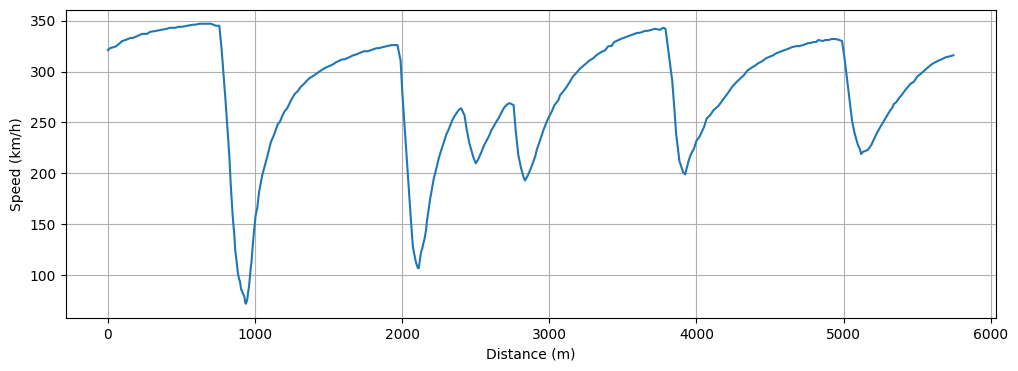

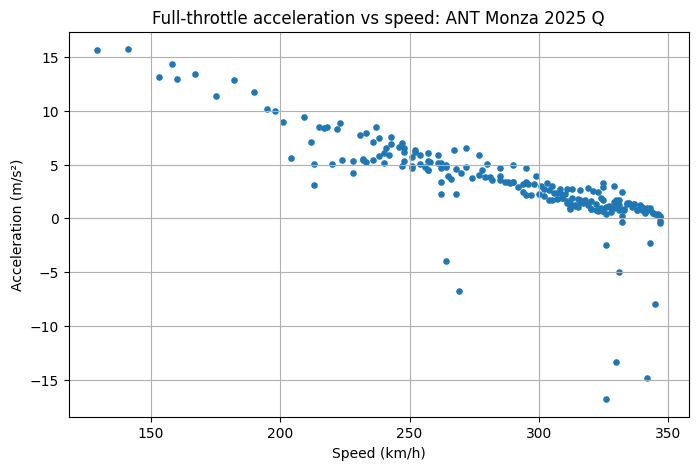

216 full-throttle samples


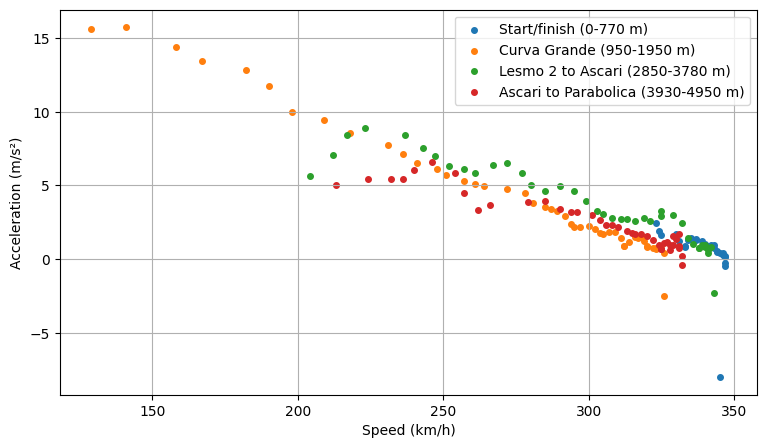

0 coast samples


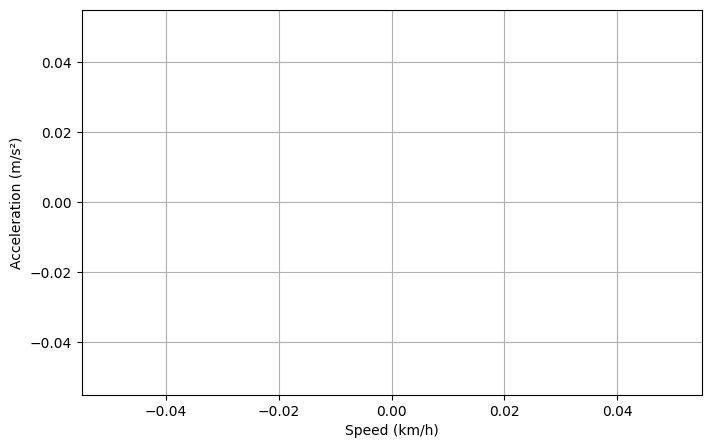

k = 6.37e-04 1/m,  P/m = 598 W/kg,  P at 800 kg = 478 kW


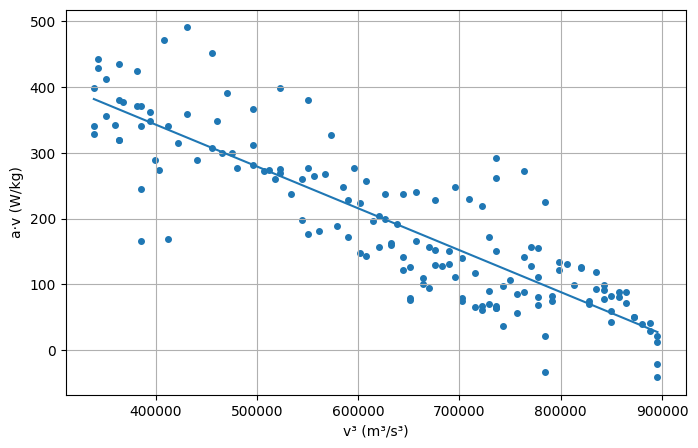

drs
8     231
12     57
14      3
Name: count, dtype: int64


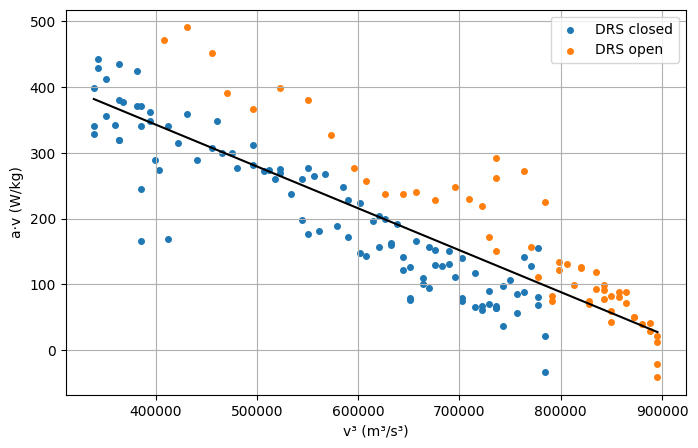

DRS closed: n=103, k=7.34e-04 1/m, P/m=627 W/kg, P at 800 kg=502 kW
DRS open: n=56, k=9.28e-04 1/m, P/m=865 W/kg, P at 800 kg=692 kW


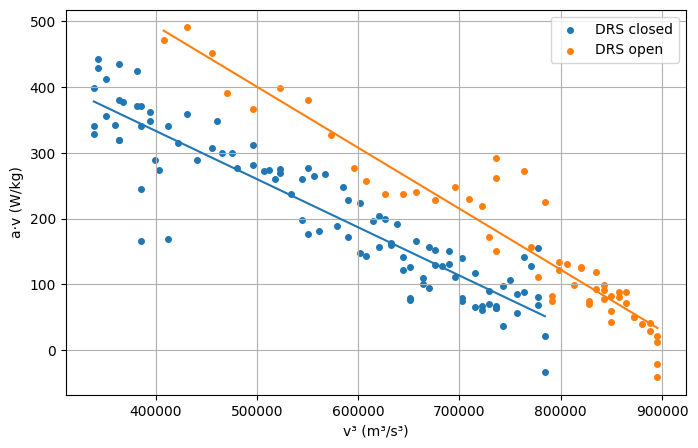

4689 race samples, 92 coast samples


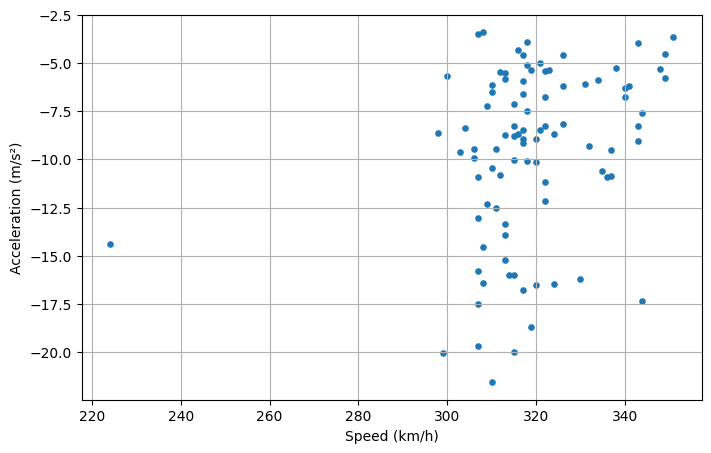

7 clean coast samples


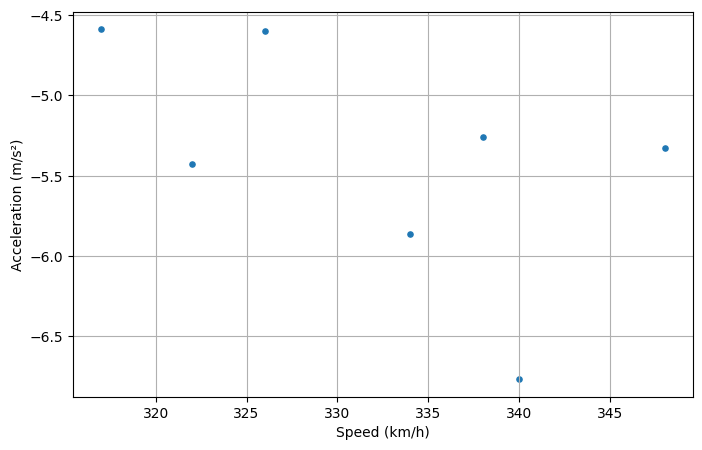

            speed      p   n
bin                         
(200, 220]  212.0  464.0  10
(220, 240]  232.0  457.0  17
(240, 260]  250.0  495.0  23
(260, 280]  268.0  483.0  18
(280, 300]  291.0  484.0  18
(300, 320]  311.0  456.0  32
(320, 340]  327.0  444.0  22


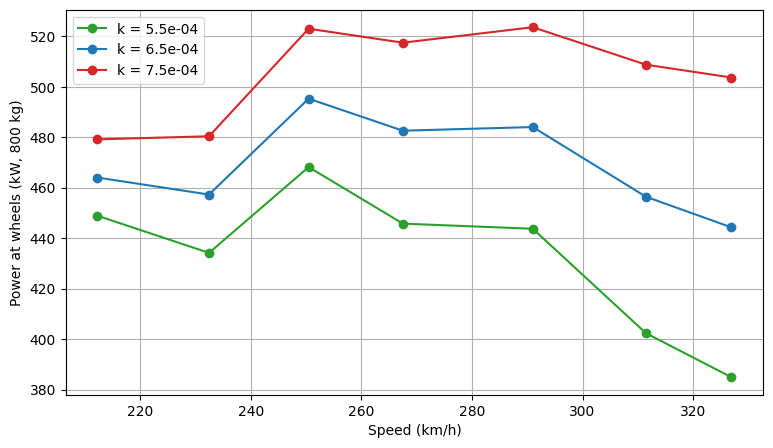

2026 Monza ANT #12: lap 10, 81.882 s, 310 samples, 5727 m


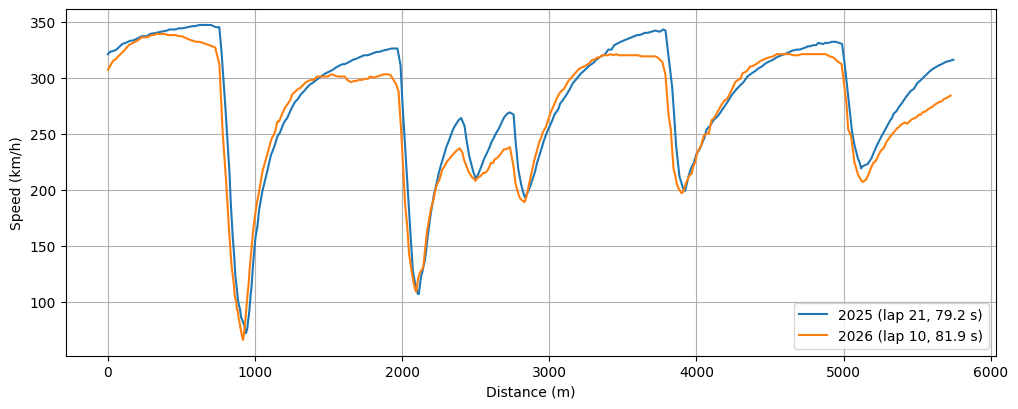

Top speed 2025: 347 km/h
Top speed 2026: 339 km/h


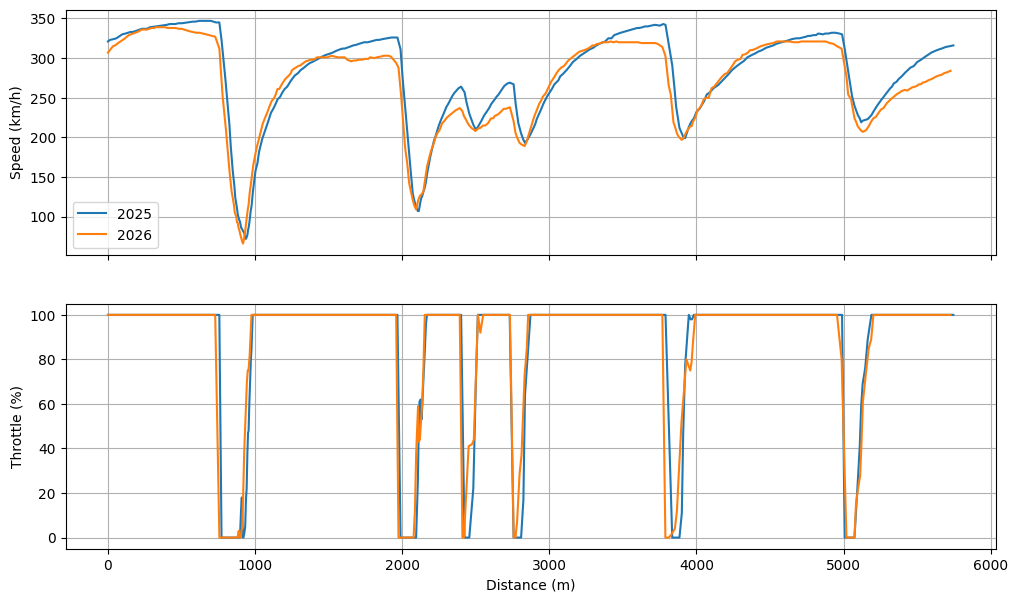

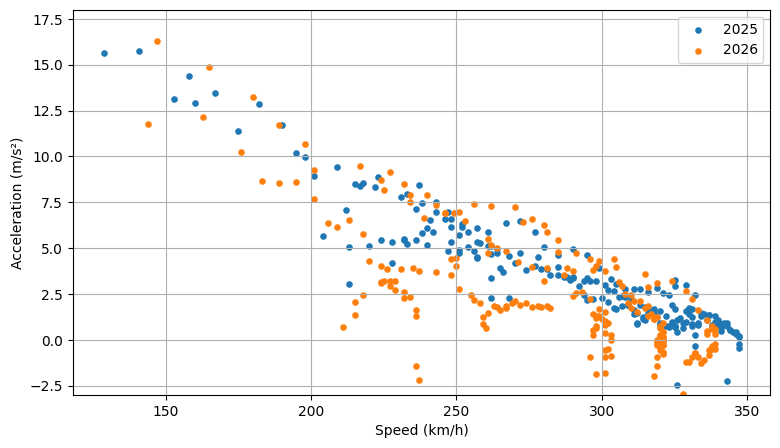

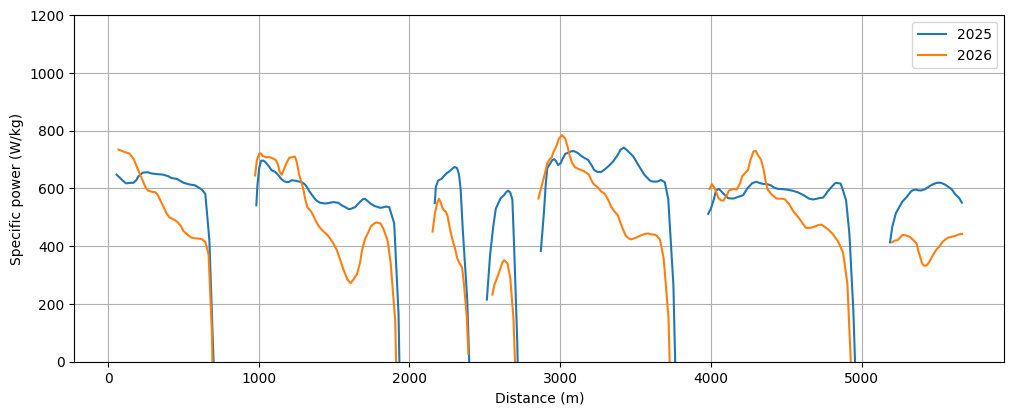

    circuit_short_name                 date_start
0            Melbourne  2026-03-08T04:00:00+00:00
1             Shanghai  2026-03-15T07:00:00+00:00
2               Suzuka  2026-03-29T05:00:00+00:00
3               Sakhir  2026-04-12T15:00:00+00:00
4               Jeddah  2026-04-19T17:00:00+00:00
5                Miami  2026-05-03T17:00:00+00:00
6             Montreal  2026-05-24T20:00:00+00:00
7          Monte Carlo  2026-06-07T13:00:00+00:00
8            Catalunya  2026-06-14T13:00:00+00:00
9            Spielberg  2026-06-28T13:00:00+00:00
10         Silverstone  2026-07-05T14:00:00+00:00
11   Spa-Francorchamps  2026-07-19T13:00:00+00:00
12         Hungaroring  2026-07-26T13:00:00+00:00
13           Zandvoort  2026-08-23T13:00:00+00:00
14               Monza  2026-09-06T13:00:00+00:00
15             Madring  2026-09-13T13:00:00+00:00
16                Baku  2026-09-26T11:00:00+00:00
17        Kuala Lumpur  2026-10-04T07:00:00+00:00
18           Singapore  2026-10-11T12:00:00+00:00


HTTPError: 429 Client Error: Too Many Requests for url: https://api.openf1.org/v1/laps?session_key=11287&driver_number=12

In [42]:
import requests, pandas as pd, numpy as np

base = 'https://api.openf1.org/v1/'

def get(endpoint, query):
    r = requests.get(base + endpoint + '?' + query)
    r.raise_for_status()
    return pd.DataFrame(r.json())

s = get('sessions', 'year=2025&circuit_short_name=Monza')
print(s[['session_name', 'session_key', 'date_start']])

qkey =9908          # the Qualifying session_key from cell 1

d = get('drivers', f'session_key={qkey}')
print(d[['name_acronym', 'driver_number', 'team_name']])

num = int(d.loc[d['name_acronym'] == 'ANT', 'driver_number'].iloc[0])
print('Antonelli is number', num)

laps = get('laps', f'session_key={qkey}&driver_number={num}')
laps = laps.dropna(subset=['lap_duration'])
best = laps.loc[laps['lap_duration'].idxmin()]
print(best['lap_number'], best['lap_duration'])

start = pd.to_datetime(best['date_start'])
end   = start + pd.to_timedelta(best['lap_duration'], unit='s')
fmt   = lambda t: t.isoformat().replace('+', '%2B')

car = get('car_data',
          f"session_key={9908}&driver_number={12}&date>={fmt(start)}&date<={fmt(end)}")
car['date'] = pd.to_datetime(car['date'])
car = car.sort_values('date').reset_index(drop=True)
car['t'] = (car['date'] - car['date'].iloc[0]).dt.total_seconds()

v = car['speed'].values / 3.6
car['Distance'] = np.r_[0, np.cumsum((v[1:] + v[:-1]) / 2 * np.diff(car['t'].values))]

car.to_csv('ant_monza_2025_q.csv', index=False)
print(len(car), 'samples, lap length about', round(car['Distance'].iloc[-1]), 'm')

import matplotlib.pyplot as plt
plt.figure(figsize=(12,4))
plt.plot(car['Distance'], car['speed']); plt.xlabel('Distance (m)'); plt.ylabel('Speed (km/h)'); plt.grid()

car = car.sort_values('t').reset_index(drop=True)
car['v'] = car['speed'] / 3.6                      # m/s
car['a'] = np.gradient(car['v'], car['t'])         # m/s^2
car['a_s'] = car['a'].rolling(3, center=True).mean()   # light smoothing

full = car[(car['throttle'] >= 99) & (car['brake'] == 0)].dropna(subset=['a_s'])

plt.figure(figsize=(8, 5))
plt.scatter(full['speed'], full['a_s'], s=14)
plt.xlabel('Speed (km/h)')
plt.ylabel('Acceleration (m/s²)')
plt.title('Full-throttle acceleration vs speed: ANT Monza 2025 Q')
plt.grid(True)
plt.show()
print(len(full), 'full-throttle samples')

segs = {
    'Start/finish (0-770 m)':     (0, 770),
    'Curva Grande (950-1950 m)':  (950, 1950),
    'Lesmo 2 to Ascari (2850-3780 m)': (2850, 3780),
    'Ascari to Parabolica (3930-4950 m)': (3930, 4950),
}

plt.figure(figsize=(9, 5))
for name, (d0, d1) in segs.items():
    s = full[(full['Distance'] >= d0) & (full['Distance'] <= d1)]
    plt.scatter(s['speed'], s['a_s'], s=16, label=name)
plt.xlabel('Speed (km/h)')
plt.ylabel('Acceleration (m/s²)')
plt.legend()
plt.grid(True)
plt.show()

coast = car[(car['throttle'] <= 1) & (car['brake'] == 0) & (car['speed'] > 150)].dropna(subset=['a_s'])
print(len(coast), 'coast samples')

plt.figure(figsize=(8, 5))
plt.scatter(coast['speed'], coast['a_s'], s=16)
plt.xlabel('Speed (km/h)'); plt.ylabel('Acceleration (m/s²)')
plt.grid(True); plt.show()

hi = full[(full['speed'] > 250) & (full['a_s'] > -1)].copy()   # drop braking-onset artefacts
x = hi['v'] ** 3
y = hi['a_s'] * hi['v']                  # W/kg

slope, intercept = np.polyfit(x, y, 1)
k = -slope
print(f'k = {k:.2e} 1/m,  P/m = {intercept:.0f} W/kg,  P at 800 kg = {intercept * 800 / 1000:.0f} kW')

plt.figure(figsize=(8, 5))
plt.scatter(x, y, s=16)
xs = np.linspace(x.min(), x.max(), 50)
plt.plot(xs, slope * xs + intercept)
plt.xlabel('v³ (m³/s³)'); plt.ylabel('a·v (W/kg)')
plt.grid(True); plt.show()

print(car['drs'].value_counts())

hi['drs_open'] = hi['drs'] >= 10     # 8, 10, 12, 14 = open/enabled values in OpenF1
xs = np.linspace(hi['v'].min()**3, hi['v'].max()**3, 50)

plt.figure(figsize=(8, 5))
for flag, lab in [(False, 'DRS closed'), (True, 'DRS open')]:
    s = hi[hi['drs_open'] == flag]
    plt.scatter(s['v']**3, s['a_s'] * s['v'], s=16, label=lab)
plt.plot(xs, slope * xs + intercept, color='k')
plt.xlabel('v³ (m³/s³)'); plt.ylabel('a·v (W/kg)')
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(8, 5))
for flag, lab, col in [(False, 'closed', 'tab:blue'), (True, 'open', 'tab:orange')]:
    s = hi[hi['drs_open'] == flag]
    x_, y_ = s['v']**3, s['a_s'] * s['v']
    sl, ic = np.polyfit(x_, y_, 1)
    print(f'DRS {lab}: n={len(s)}, k={-sl:.2e} 1/m, P/m={ic:.0f} W/kg, P at 800 kg={ic*0.8:.0f} kW')
    plt.scatter(x_, y_, s=16, color=col, label=f'DRS {lab}')
    xs = np.linspace(x_.min(), x_.max(), 50)
    plt.plot(xs, sl * xs + ic, color=col)
plt.xlabel('v³ (m³/s³)'); plt.ylabel('a·v (W/kg)')
plt.legend(); plt.grid(True); plt.show()

import time
fmt = lambda t: t.isoformat().replace('+', '%2B')

s = get('sessions', 'year=2025&circuit_short_name=Monza')
rkey = int(s.loc[s['session_name'] == 'Race', 'session_key'].iloc[0])

rlaps = get('laps', f'session_key={rkey}&driver_number={num}')
rlaps = rlaps.dropna(subset=['lap_duration', 'date_start'])
rlaps = rlaps[(rlaps['is_pit_out_lap'] != True) & (rlaps['lap_number'].between(8, 30))].head(15)

frames = []
for _, row in rlaps.iterrows():
    start = pd.to_datetime(row['date_start'])
    end = start + pd.to_timedelta(row['lap_duration'], unit='s')
    c = get('car_data', f"session_key={rkey}&driver_number={num}&date>={fmt(start)}&date<={fmt(end)}")
    c['date'] = pd.to_datetime(c['date'])
    c['t'] = (c['date'] - c['date'].iloc[0]).dt.total_seconds()
    c['v'] = c['speed'] / 3.6
    c['a'] = np.gradient(c['v'], c['t'])
    c['a_s'] = c['a'].rolling(3, center=True).mean()
    c['lap'] = row['lap_number']
    frames.append(c)
    time.sleep(0.5)                      # be polite to the API

race = pd.concat(frames, ignore_index=True)
coast = race[(race['throttle'] <= 1) & (race['brake'] == 0) & (race['speed'] > 200)].dropna(subset=['a_s'])
print(len(race), 'race samples,', len(coast), 'coast samples')

plt.figure(figsize=(8, 5))
plt.scatter(coast['speed'], coast['a_s'], s=14)
plt.xlabel('Speed (km/h)'); plt.ylabel('Acceleration (m/s²)'); plt.grid(True); plt.show()

race['brake_near'] = race.groupby('lap')['brake'].transform(
    lambda s: s.rolling(5, center=True, min_periods=1).max())

clean = race[(race['throttle'] <= 1) & (race['brake_near'] == 0) &
             (race['drs'] < 10) & (race['speed'] > 250)].dropna(subset=['a_s'])
print(len(clean), 'clean coast samples')

plt.figure(figsize=(8, 5))
plt.scatter(clean['speed'], clean['a_s'], s=14)
plt.xlabel('Speed (km/h)'); plt.ylabel('Acceleration (m/s²)'); plt.grid(True); plt.show()

fc = full[(full['speed'] > 200) & (full['a_s'] > -1) & (full['drs'] < 10)].copy()
bins = np.arange(200, 360, 20)
fc['bin'] = pd.cut(fc['speed'], bins)

plt.figure(figsize=(9, 5))
for k, col in [(5.5e-4, 'tab:green'), (6.5e-4, 'tab:blue'), (7.5e-4, 'tab:red')]:
    fc['p'] = fc['v'] * (fc['a_s'] + k * fc['v']**2) * 0.8     # kW at 800 kg
    g = fc.groupby('bin', observed=True).agg(speed=('speed', 'mean'), p=('p', 'median'), n=('p', 'size'))
    plt.plot(g['speed'], g['p'], 'o-', color=col, label=f'k = {k:.1e}')
    if k == 6.5e-4:
        print(g.round(0))
plt.xlabel('Speed (km/h)'); plt.ylabel('Power at wheels (kW, 800 kg)')
plt.legend(); plt.grid(True); plt.show()

def pull_best_lap(year, circuit, session_name='Qualifying', acr='ANT'):
    s = get('sessions', f'year={year}&circuit_short_name={circuit}')
    key = int(s.loc[s['session_name'] == session_name, 'session_key'].iloc[0])
    d = get('drivers', f'session_key={key}')
    num = int(d.loc[d['name_acronym'] == acr, 'driver_number'].iloc[0])
    laps = get('laps', f'session_key={key}&driver_number={num}').dropna(subset=['lap_duration', 'date_start'])
    best = laps.loc[laps['lap_duration'].idxmin()]
    start = pd.to_datetime(best['date_start'])
    end = start + pd.to_timedelta(best['lap_duration'], unit='s')
    c = get('car_data', f"session_key={key}&driver_number={num}&date>={fmt(start)}&date<={fmt(end)}")
    c['date'] = pd.to_datetime(c['date'])
    c = c.sort_values('date').reset_index(drop=True)
    c['t'] = (c['date'] - c['date'].iloc[0]).dt.total_seconds()
    c['v'] = c['speed'] / 3.6
    dt = np.diff(c['t'].values)
    c['Distance'] = np.concatenate([[0], np.cumsum(0.5 * (c['v'].values[1:] + c['v'].values[:-1]) * dt)])
    c['a'] = np.gradient(c['v'], c['t'])
    c['a_s'] = c['a'].rolling(3, center=True).mean()
    print(f"{year} {circuit} {acr} #{num}: lap {int(best['lap_number'])}, {best['lap_duration']:.3f} s, "
          f"{len(c)} samples, {c['Distance'].iloc[-1]:.0f} m")
    return c

car26 = pull_best_lap(2026, 'Monza')
car26.to_csv('ant_monza_2026_q.csv')

plt.figure(figsize=(12, 4.5))
plt.plot(car['Distance'], car['speed'], label='2025 (lap 21, 79.2 s)')
plt.plot(car26['Distance'], car26['speed'], label='2026 (lap 10, 81.9 s)')
plt.xlabel('Distance (m)'); plt.ylabel('Speed (km/h)')
plt.legend(); plt.grid(True); plt.show()

print('Top speed 2025:', car['speed'].max(), 'km/h')
print('Top speed 2026:', car26['speed'].max(), 'km/h')

fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax[0].plot(car['Distance'], car['speed'], label='2025')
ax[0].plot(car26['Distance'], car26['speed'], label='2026')
ax[0].set_ylabel('Speed (km/h)'); ax[0].legend(); ax[0].grid(True)
ax[1].plot(car['Distance'], car['throttle'], label='2025')
ax[1].plot(car26['Distance'], car26['throttle'], label='2026')
ax[1].set_ylabel('Throttle (%)'); ax[1].set_xlabel('Distance (m)'); ax[1].grid(True)
plt.show()

full26 = car26[(car26['throttle'] >= 99) & (car26['brake'] == 0)].dropna(subset=['a_s'])
plt.figure(figsize=(9, 5))
plt.scatter(full['speed'], full['a_s'], s=14, label='2025')
plt.scatter(full26['speed'], full26['a_s'], s=14, label='2026')
plt.ylim(-3, 18)
plt.xlabel('Speed (km/h)'); plt.ylabel('Acceleration (m/s²)')
plt.legend(); plt.grid(True); plt.show()

k = 6.5e-4
for df in (car, car26):
    df['p'] = df['v'] * (df['a_s'] + k * df['v']**2)          # W/kg
    df['p_plot'] = df['p'].rolling(5, center=True).mean().where(df['throttle'] >= 99)

plt.figure(figsize=(12, 4.5))
plt.plot(car['Distance'], car['p_plot'], label='2025')
plt.plot(car26['Distance'], car26['p_plot'], label='2026')
plt.ylim(0, 1200)
plt.xlabel('Distance (m)'); plt.ylabel('Specific power (W/kg)')
plt.legend(); plt.grid(True); plt.show()

car.to_csv('ant_monza_2025_q.csv', index=False)
car26.to_csv('ant_monza_2026_q.csv', index=False)

print(get('sessions', 'year=2026&session_name=Race')[['circuit_short_name', 'date_start']])

def top5(year, circuit):
    s = get('sessions', f'year={year}&circuit_short_name={circuit}')
    key = int(s.loc[s['session_name'] == 'Race', 'session_key'].iloc[0])
    r = get('session_result', f'session_key={key}')
    d = get('drivers', f'session_key={key}')[['driver_number', 'name_acronym', 'team_name']]
    r = r.merge(d, on='driver_number').sort_values('position')
    print(year, circuit)
    print(r[['position', 'name_acronym', 'team_name', 'gap_to_leader']].head(5).to_string(index=False))
    print()

for c in ['Spa-Francorchamps', 'Miami', 'Montreal']:   # use the names printed above if these fail
    top5(2026, c)

k = 6.5e-4

def straight_table(df, label, min_len=300, trim=2):
    df = df.reset_index(drop=True).copy()
    df['p_s'] = (df['v'] * (df['a_s'] + k * df['v']**2)).rolling(5, center=True, min_periods=3).mean()
    ft = (df['throttle'] >= 99) & (df['brake'] == 0)
    rid = (ft != ft.shift()).cumsum()
    rows = []
    for _, g in df[ft].groupby(rid[ft]):
        g = g.iloc[:-trim] if trim else g
        g = g[g['speed'] > 200]
        if len(g) < 8 or g['Distance'].iloc[-1] - g['Distance'].iloc[0] < min_len:
            continue
        n = max(3, len(g) // 4)
        p0, p1 = g['p_s'].iloc[:n].mean(), g['p_s'].iloc[-n:].mean()
        clip = g[(g['speed'] > 250) & (g['a_s'] < 1.0)]
        rows.append({'year': label,
                     'start_m': round(g['Distance'].iloc[0]), 'end_m': round(g['Distance'].iloc[-1]),
                     'v_start': round(g['speed'].iloc[0]), 'v_end': round(g['speed'].iloc[-1]),
                     'P_start': round(p0), 'P_end': round(p1),
                     'drop_pct': round(100 * (p0 - p1) / p0),
                     'clip_speed': round(clip['speed'].iloc[0]) if len(clip) else None})
    return pd.DataFrame(rows)

tab = pd.concat([straight_table(car, '2025'), straight_table(car26, '2026')], ignore_index=True)
print(tab.to_string(index=False))
tab.to_csv('monza_straights_table.csv', index=False)

def binned_power(df, label, edges=(250, 270, 290, 310, 330)):
    d = df.copy()
    d['p_s'] = (d['v'] * (d['a_s'] + k * d['v']**2)).rolling(5, center=True, min_periods=3).mean()
    f = d[(d['throttle'] >= 99) & (d['brake'] == 0) & (d['a_s'] > -3)].copy()
    f['bin'] = pd.cut(f['speed'], list(edges))
    return f.groupby('bin', observed=True)['p_s'].agg(['median', 'count']).rename(
        columns={'median': label, 'count': 'n_' + label})

cmp_ = pd.concat([binned_power(car, '2025'), binned_power(car26, '2026')], axis=1)
cmp_['diff_pct'] = (100 * (cmp_['2026'] - cmp_['2025']) / cmp_['2025']).round(0)
print(cmp_.round(0))

car_m25 = pull_best_lap(2025, 'Montreal')
car_m26 = pull_best_lap(2026, 'Montreal')
car_m25.to_csv('ant_montreal_2025_q.csv', index=False)
car_m26.to_csv('ant_montreal_2026_q.csv', index=False)

k = 6.5e-4
for df in (car_m25, car_m26):
    df['p'] = df['v'] * (df['a_s'] + k * df['v']**2)          # W/kg
    df['p_plot'] = df['p'].rolling(5, center=True).mean().where(df['throttle'] >= 99)

print('Top speed 2025:', car_m25['speed'].max(), 'km/h')
print('Top speed 2026:', car_m26['speed'].max(), 'km/h')

fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax[0].plot(car_m25['Distance'], car_m25['speed'], label='2025')
ax[0].plot(car_m26['Distance'], car_m26['speed'], label='2026')
ax[0].set_ylabel('Speed (km/h)'); ax[0].legend(); ax[0].grid(True)
ax[1].plot(car_m25['Distance'], car_m25['p_plot'], label='2025')
ax[1].plot(car_m26['Distance'], car_m26['p_plot'], label='2026')
ax[1].set_ylim(0, 1200)
ax[1].set_ylabel('Specific power (W/kg)'); ax[1].set_xlabel('Distance (m)')
ax[1].legend(); ax[1].grid(True)
plt.show()

tab_m = pd.concat([straight_table(car_m25, '2025'), straight_table(car_m26, '2026')], ignore_index=True)
print(tab_m.to_string(index=False))
tab_m.to_csv('montreal_straights_table.csv', index=False)

import time

def get(endpoint, query, tries=6):
    for i in range(tries):
        r = requests.get(base + endpoint + '?' + query)
        if r.status_code == 429:
            time.sleep(3 * (i + 1))
            continue
        r.raise_for_status()
        return pd.DataFrame(r.json())
    raise RuntimeError('still rate limited: ' + endpoint)

time.sleep(20)                                   # let the limit reset
car_m26 = pull_best_lap(2026, 'Montreal')
car_m25.to_csv('ant_montreal_2025_q.csv', index=False)
car_m26.to_csv('ant_montreal_2026_q.csv', index=False)

k = 6.5e-4
for df in (car_m25, car_m26):
    df['p'] = df['v'] * (df['a_s'] + k * df['v']**2)          # W/kg
    df['p_plot'] = df['p'].rolling(5, center=True).mean().where(df['throttle'] >= 99)

print('Top speed 2025:', car_m25['speed'].max(), 'km/h')
print('Top speed 2026:', car_m26['speed'].max(), 'km/h')

fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax[0].plot(car_m25['Distance'], car_m25['speed'], label='2025')
ax[0].plot(car_m26['Distance'], car_m26['speed'], label='2026')
ax[0].set_ylabel('Speed (km/h)'); ax[0].legend(); ax[0].grid(True)
ax[1].plot(car_m25['Distance'], car_m25['p_plot'], label='2025')
ax[1].plot(car_m26['Distance'], car_m26['p_plot'], label='2026')
ax[1].set_ylim(0, 1200)
ax[1].set_ylabel('Specific power (W/kg)'); ax[1].set_xlabel('Distance (m)')
ax[1].legend(); ax[1].grid(True)
plt.show()

tab_m = pd.concat([straight_table(car_m25, '2025'), straight_table(car_m26, '2026')], ignore_index=True)
print(tab_m.to_string(index=False))
tab_m.to_csv('montreal_straights_table.csv', index=False)

from google.colab import files
col = {'2025': '#1f77b4', '2026': '#e8710a'}

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(car['Distance'], car['speed'], color=col['2025'], label='2025')
ax.plot(car26['Distance'], car26['speed'], color=col['2026'], label='2026')
ax.set_xlabel('Distance (m)'); ax.set_ylabel('Speed (km/h)')
ax.set_title('Monza qualifying lap: the 2026 car stops gaining speed on the straights')
ax.legend(frameon=False); ax.grid(alpha=0.3)
fig.savefig('monza_speed.png', dpi=200, bbox_inches='tight')
files.download('monza_speed.png')

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(car['Distance'], car['p_plot'], color=col['2025'], label='2025')
ax.plot(car26['Distance'], car26['p_plot'], color=col['2026'], label='2026')
ax.set_ylim(0, 1000)
ax.set_xlabel('Distance (m)'); ax.set_ylabel('Specific power at full throttle (W/kg)')
ax.set_title('2025 power holds along each straight; 2026 starts higher and fades')
ax.legend(frameon=False); ax.grid(alpha=0.3)
fig.savefig('monza_power.png', dpi=200, bbox_inches='tight')
files.download('monza_power.png')

2026 Montreal ANT #12: lap 23, 72.646 s, 281 samples, 4299 m
Top speed 2025: 333 km/h
Top speed 2026: 331 km/h


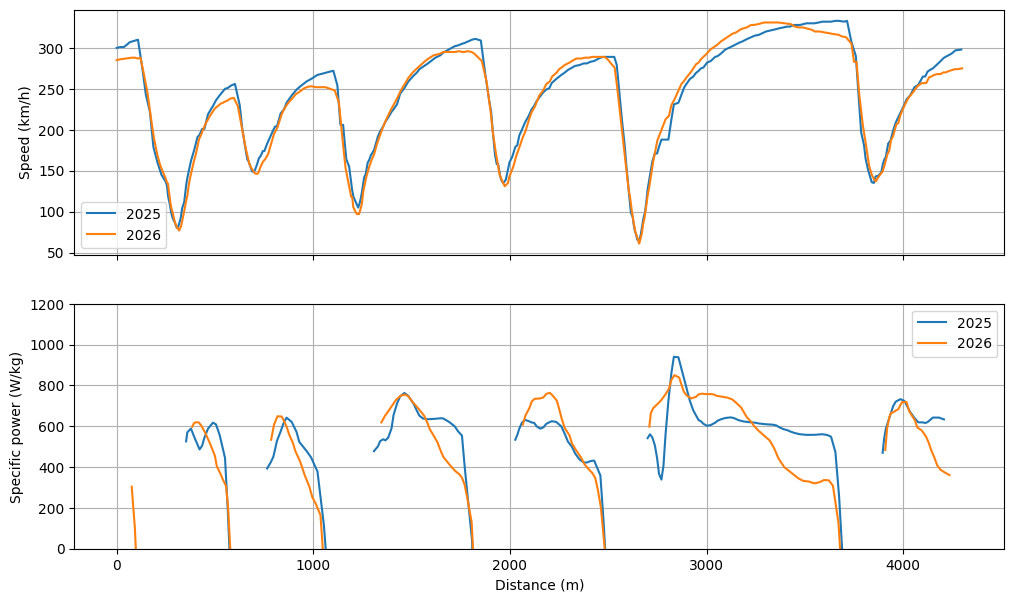

year  start_m  end_m  v_start  v_end  P_start  P_end  drop_pct  clip_speed
2025     1355   1807      204    310      571    435        24         NaN
2025     2077   2476      209    289      618    355        43       289.0
2025     2821   3674      213    333      749    519        31       326.0
2026     1364   1805      209    295      702    281        60       295.0
2026     2099   2482      214    289      724    243        66       288.0
2026     2792   3671      213    316      786    308        61       329.0


In [43]:
import time

def get(endpoint, query, tries=6):
    for i in range(tries):
        r = requests.get(base + endpoint + '?' + query)
        if r.status_code == 429:
            time.sleep(3 * (i + 1))
            continue
        r.raise_for_status()
        return pd.DataFrame(r.json())
    raise RuntimeError('still rate limited: ' + endpoint)

time.sleep(20)
if 'car_m25' not in globals():
    car_m25 = pull_best_lap(2025, 'Montreal')
car_m26 = pull_best_lap(2026, 'Montreal')
car_m25.to_csv('ant_montreal_2025_q.csv', index=False)
car_m26.to_csv('ant_montreal_2026_q.csv', index=False)

k = 6.5e-4
for df in (car_m25, car_m26):
    df['p'] = df['v'] * (df['a_s'] + k * df['v']**2)
    df['p_plot'] = df['p'].rolling(5, center=True).mean().where(df['throttle'] >= 99)

print('Top speed 2025:', car_m25['speed'].max(), 'km/h')
print('Top speed 2026:', car_m26['speed'].max(), 'km/h')

fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax[0].plot(car_m25['Distance'], car_m25['speed'], label='2025')
ax[0].plot(car_m26['Distance'], car_m26['speed'], label='2026')
ax[0].set_ylabel('Speed (km/h)'); ax[0].legend(); ax[0].grid(True)
ax[1].plot(car_m25['Distance'], car_m25['p_plot'], label='2025')
ax[1].plot(car_m26['Distance'], car_m26['p_plot'], label='2026')
ax[1].set_ylim(0, 1200)
ax[1].set_ylabel('Specific power (W/kg)'); ax[1].set_xlabel('Distance (m)')
ax[1].legend(); ax[1].grid(True)
plt.show()

tab_m = pd.concat([straight_table(car_m25, '2025'), straight_table(car_m26, '2026')], ignore_index=True)
print(tab_m.to_string(index=False))
tab_m.to_csv('montreal_straights_table.csv', index=False)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

NameError: name 'save_plots' is not defined

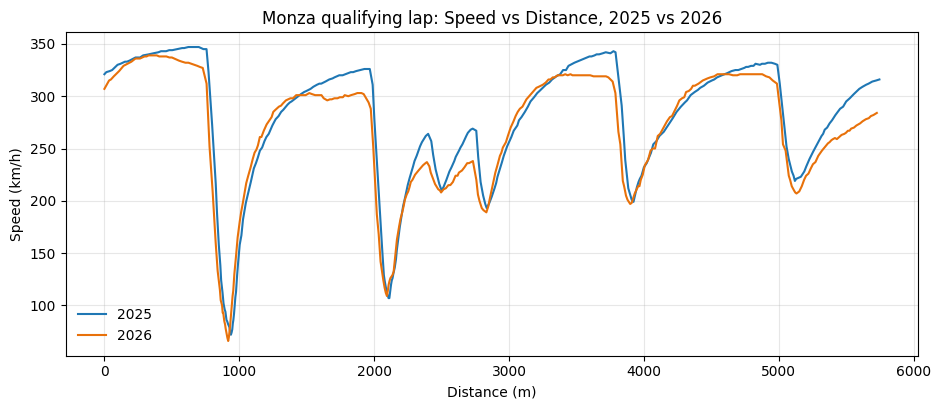

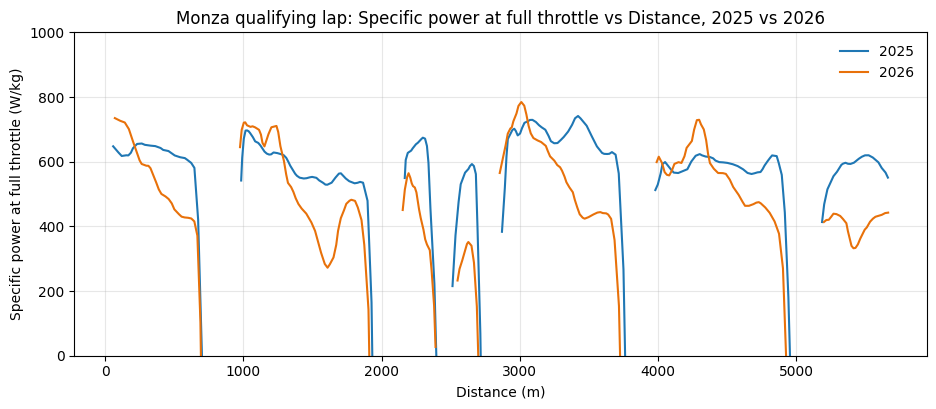

In [47]:
from google.colab import files
col = {'2025': '#1f77b4', '2026': '#e8710a'}

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(car['Distance'], car['speed'], color=col['2025'], label='2025')
ax.plot(car26['Distance'], car26['speed'], color=col['2026'], label='2026')
ax.set_xlabel('Distance (m)'); ax.set_ylabel('Speed (km/h)')
ax.set_title('Monza qualifying lap: Speed vs Distance, 2025 vs 2026')
ax.legend(frameon=False); ax.grid(alpha=0.3)
fig.savefig('monza_speed.png', dpi=200, bbox_inches='tight')
files.download('monza_speed.png')

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(car['Distance'], car['p_plot'], color=col['2025'], label='2025')
ax.plot(car26['Distance'], car26['p_plot'], color=col['2026'], label='2026')
ax.set_ylim(0, 1000)
ax.set_xlabel('Distance (m)'); ax.set_ylabel('Specific power at full throttle (W/kg)')
ax.set_title('Monza qualifying lap: Specific power at full throttle vs Distance, 2025 vs 2026')
ax.legend(frameon=False); ax.grid(alpha=0.3)
fig.savefig('monza_power.png', dpi=200, bbox_inches='tight')
files.download('monza_power.png')

save_plots(car, car26, 'monza',speed_title='Monza qualifying lap: speed vs distance, 2025 vs 2026',power_title='Monza qualifying lap: specific power at full throttle vs distance, 2025 vs 2026')